# 01 — Data Exploration

**Goal** – Audit the three raw tables (`videos`, `creator_daily`,
`engagement_daily`): characterise rows, columns, nulls, date ranges,
creator distribution, join integrity, and engagement-metric distributions.

**Input** – `data/raw/*.parquet` downloaded by `scripts/download_data.py`.

**Conclusion** –
Three tables downloaded cleanly:
`videos` 209 543 rows × 33 cols (175.1 MB, dates 2024-06-24–2024-11-09),
`creator_daily` 278 433 × 7 (3.1 MB),
`engagement_daily` 6 068 955 × 10 (31.8 MB, **0 nulls anywhere**).
1 872 unique creators; median 69 videos per creator (min 5, max 2 218).
Join integrity is perfect: every `video_id` appears in both `videos` and
`engagement_daily`; every `author_id` in both `videos` and `creator_daily`.
Notable nulls: `transcript` 60.3 %, `sticker_text` 52.8 % (use `gpt_summary`
which is 0 % null); `enterprise_verified` in `creator_daily` is 100 % null.
`play_count` is highly right-skewed (median 570, max 44 442 900) —
log-scale transformation is required before modelling.


In [1]:
import sys
if "google.colab" in sys.modules:
    import subprocess, os
    subprocess.run(
        ["git", "clone", "--depth", "1",
         "https://github.com/Shopska/Personalized_analysis_of_social_media.git", "repo"],
        check=True,
    )
    os.chdir("repo")
    subprocess.run(
        ["pip", "install", "-q", "-r", "requirements.txt", "-r", "requirements-dev.txt"],
        check=True,
    )
    subprocess.run(["pip", "install", "-q", "-e", "."], check=True)
    subprocess.run(["python", "scripts/download_data.py"], check=True)


In [2]:
import os
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

# Ensure working directory is the project root when opened from notebooks/
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from IPython.display import display
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})


In [3]:
from creator_analytics.config import load_config
from creator_analytics.data import load_raw_table

cfg    = load_config("config/default.yaml")
RAW    = cfg["paths"]["raw_dir"]
FIGS   = Path("results/figures")
FIGS.mkdir(parents=True, exist_ok=True)

videos        = load_raw_table(RAW, "videos")
creator_daily = load_raw_table(RAW, "creator_daily")
engagement    = load_raw_table(RAW, "engagement_daily")

def _mb(t: str) -> float:
    return Path(RAW).joinpath(f"{t}.parquet").stat().st_size / 1_048_576

for t, df in [("videos", videos), ("creator_daily", creator_daily),
               ("engagement_daily", engagement)]:
    print(f"{t:<22} {len(df):>9,} rows  {len(df.columns):>2} cols  {_mb(t):>7.1f} MB")


videos                   209,543 rows  33 cols    175.1 MB
creator_daily            278,433 rows   7 cols      3.1 MB
engagement_daily       6,068,955 rows  10 cols     31.8 MB


## Table schemas and null rates

In [4]:
def _schema(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for col in df.columns:
        try:
            nu = df[col].nunique()
        except TypeError:
            nu = None          # unhashable type (e.g. list/array column)
        rows.append({
            "column": col,
            "dtype": str(df[col].dtype),
            "null_%": round(df[col].isna().mean() * 100, 1),
            "n_unique": nu,
        })
    return pd.DataFrame(rows).set_index("column")

print("### videos")
display(_schema(videos))
print("### creator_daily")
display(_schema(creator_daily))
print("### engagement_daily")
display(_schema(engagement))


### videos


,dtype,null_%,n_unique
column,,,
video_id,str,0.0,209543.0
author_id,str,0.0,1872.0
create_time,str,0.0,207162.0
create_date,str,0.0,137.0
duration,float64,0.0,28784.0
ratio,str,0.0,5.0
desc_language,str,0.0,2.0
is_english,int64,0.0,2.0
desc,str,9.1,174800.0


### creator_daily


,dtype,null_%,n_unique
column,,,
author_id,str,0.0,1872
date,str,0.0,161
follower_count,float64,0.1,88331
following_count,float64,0.1,9775
total_favorited,int64,0.0,220238
video_count,float64,0.0,6661
enterprise_verified,str,100.0,0


### engagement_daily


,dtype,null_%,n_unique
column,,,
video_id,str,0.0,209543
date,str,0.0,159
days_since_post,int64,0.0,31
play_count,int64,0.0,262837
like_count,int64,0.0,84133
comment_count,int64,0.0,7046
share_count,int64,0.0,21174
collect_count,int64,0.0,21441
download_count,int64,0.0,5609


## Date ranges

In [5]:
for name, df, col in [
    ("videos",        videos,        "create_date"),
    ("creator_daily", creator_daily, "date"),
    ("engagement",    engagement,    "date"),
]:
    s = pd.to_datetime(df[col], errors="coerce")
    print(f"{name:<22} {s.min().date()} – {s.max().date()}")


videos                 2024-06-24 – 2024-11-09
creator_daily          2024-06-24 – 2024-12-09


engagement             2024-06-24 – 2024-12-09


## Videos per creator

In [6]:
vc = videos["author_id"].value_counts()
print(f"Unique creators : {len(vc):,}")
print(f"Min videos      : {vc.min()}")
print(f"Median videos   : {vc.median():.0f}")
print(f"Max videos      : {vc.max()}")


Unique creators : 1,872
Min videos      : 5
Median videos   : 69
Max videos      : 2218


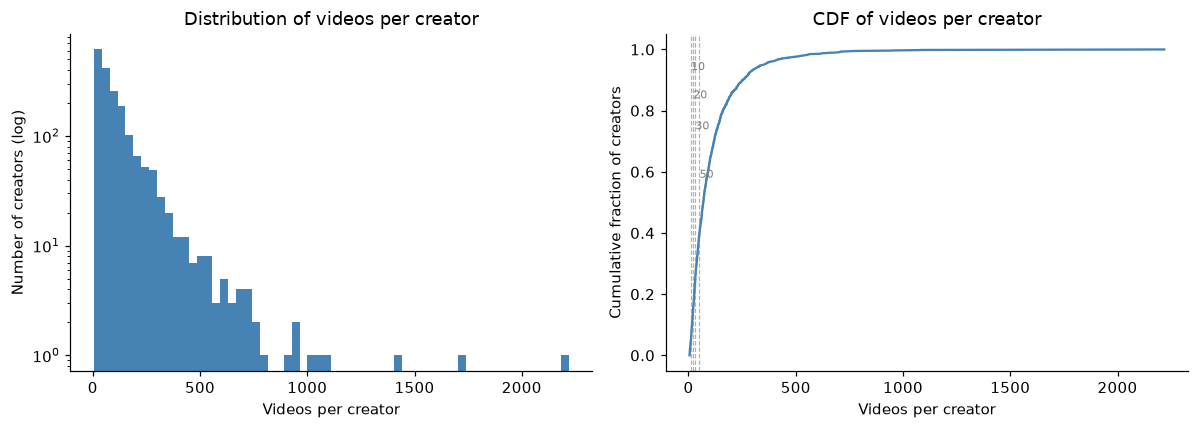

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Histogram (log y)
axes[0].hist(vc.values, bins=60, color="steelblue", edgecolor="none", log=True)
axes[0].set_xlabel("Videos per creator")
axes[0].set_ylabel("Number of creators (log)")
axes[0].set_title("Distribution of videos per creator")

# CDF
sorted_vc = np.sort(vc.values)
axes[1].plot(sorted_vc, np.linspace(0, 1, len(sorted_vc)), color="steelblue")
axes[1].set_xlabel("Videos per creator")
axes[1].set_ylabel("Cumulative fraction of creators")
axes[1].set_title("CDF of videos per creator")
for thresh in [10, 20, 30, 50]:
    pct = (vc >= thresh).mean()
    axes[1].axvline(thresh, color="gray", linestyle="--", linewidth=0.8, alpha=0.6)
    axes[1].text(thresh + 2, pct - 0.03, f"{thresh}", fontsize=7, color="gray")

fig.tight_layout()
fig.savefig(FIGS / "nb01_creator_distribution.png", dpi=120)
plt.show()


In [8]:
rows = [(t, int((vc >= t).sum()), int(vc[vc >= t].sum())) for t in [10, 20, 30, 50]]
display(
    pd.DataFrame(rows, columns=["min_videos_per_creator", "creators_kept", "videos_kept"])
    .set_index("min_videos_per_creator")
)


,creators_kept,videos_kept
min_videos_per_creator,,
10,1802,209051
20,1629,206519
30,1439,201832
50,1143,190260


## Join integrity

In [9]:
v_ids = set(videos["video_id"])
e_ids = set(engagement["video_id"])
a_ids = set(videos["author_id"])
c_ids = set(creator_daily["author_id"])

print(f"video_id in videos   only (not in engagement_daily): {len(v_ids - e_ids):,}")
print(f"video_id in eng.     only (not in videos)          : {len(e_ids - v_ids):,}")
print(f"author_id in videos  only (not in creator_daily)   : {len(a_ids - c_ids):,}")
print(f"author_id in creator only (not in videos)          : {len(c_ids - a_ids):,}")


video_id in videos   only (not in engagement_daily): 0
video_id in eng.     only (not in videos)          : 0
author_id in videos  only (not in creator_daily)   : 0
author_id in creator only (not in videos)          : 0


## `engagement_daily`: structure and metric distributions

days_since_post distribution across all rows:
  min=0  p25=7  median=14  p75=22  max=30


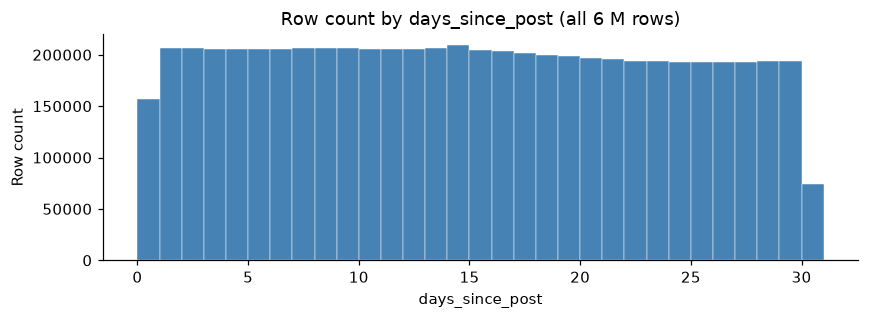

In [10]:
dsp = engagement["days_since_post"]
print("days_since_post distribution across all rows:")
print(f"  min={dsp.min()}  p25={dsp.quantile(0.25):.0f}  "
      f"median={dsp.median():.0f}  p75={dsp.quantile(0.75):.0f}  max={dsp.max()}")

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(dsp.values, bins=range(0, 32), color="steelblue", edgecolor="white", linewidth=0.3)
ax.set_xlabel("days_since_post")
ax.set_ylabel("Row count")
ax.set_title("Row count by days_since_post (all 6 M rows)")
ax.xaxis.set_major_locator(mticker.MultipleLocator(5))
fig.tight_layout()
plt.show()


In [11]:
metric_cols = ["play_count", "like_count", "comment_count",
               "share_count", "collect_count", "download_count"]

# Show stats at day 14 (full coverage)
eng14 = engagement[engagement["days_since_post"] == 14]
stats = (
    eng14[metric_cols]
    .agg(["min", "median", "mean", "max"])
    .T.astype(int)
    .rename(columns=str.title)
)
display(stats)


,Min,Median,Mean,Max
play_count,0,599,26313,37871739
like_count,0,43,2274,2820500
comment_count,0,3,33,62700
share_count,0,0,158,653973
collect_count,0,2,150,181984
download_count,0,0,13,40811


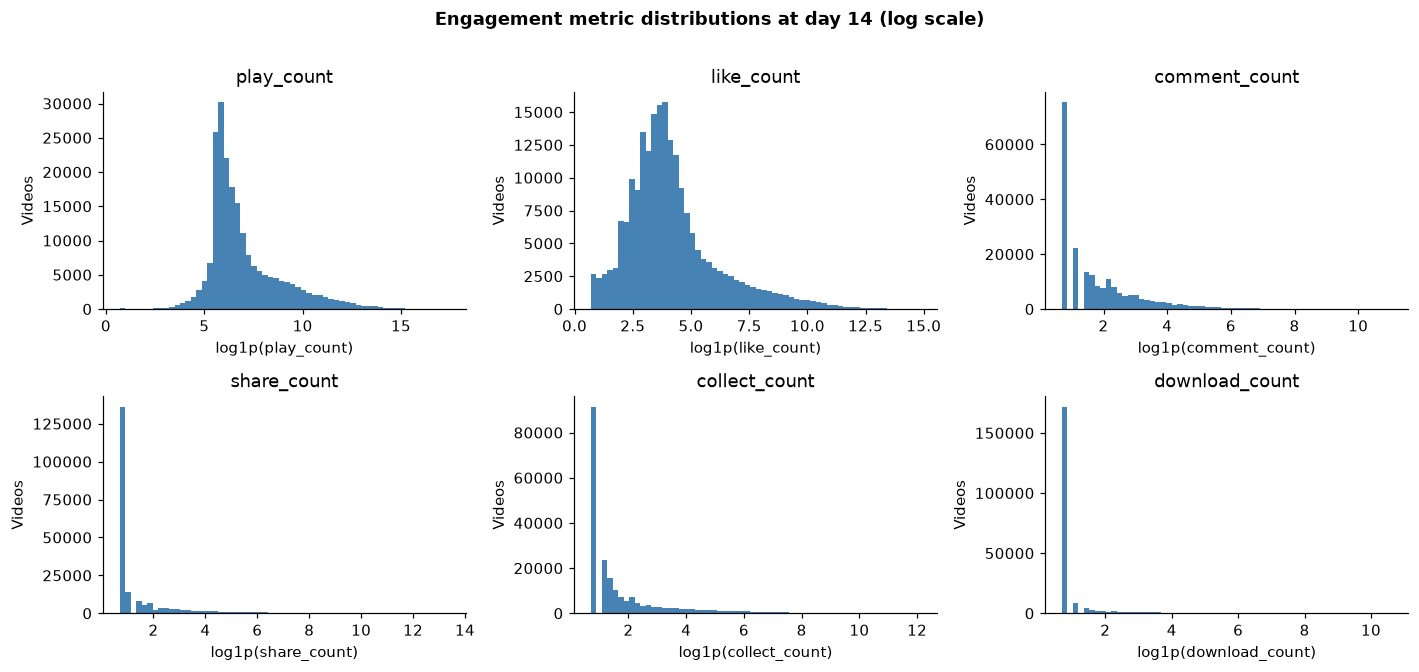

In [12]:
eng14 = engagement[engagement["days_since_post"] == 14]
metric_cols = ["play_count", "like_count", "comment_count",
               "share_count", "collect_count", "download_count"]

fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, col in zip(axes.flat, metric_cols):
    data = eng14[col].clip(lower=1)          # shift 0→1 so log1p is fine
    ax.hist(np.log1p(data), bins=60, color="steelblue", edgecolor="none")
    ax.set_xlabel(f"log1p({col})")
    ax.set_ylabel("Videos")
    ax.set_title(col)

fig.suptitle("Engagement metric distributions at day 14 (log scale)", fontweight="bold", y=1.01)
fig.tight_layout()
fig.savefig(FIGS / "nb01_engagement_distributions.png", dpi=120, bbox_inches="tight")
plt.show()
